In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [50]:
df = pd.read_csv("thyroid_cancer_risk_data.csv")
fA = df['T3_Level']
fB = df['Nodule_Size']
fC = (df[['Radiation_Exposure','Iodine_Deficiency','Smoking','Obesity']] == 'Yes').sum(axis=1)

In [51]:
df_subset = df.iloc[:150000].copy()
df_subset['is_malignant'] = (df_subset['Diagnosis'] == 'Malignant').astype(int)
df_subset['chunk_id'] = np.arange(len(df_subset)) // 30
chunk_counts = df_subset.groupby('chunk_id')['is_malignant'].sum().reset_index()
chunk_counts.columns = ['Chunk_ID', 'Malignant_Count']
fD = chunk_counts['Malignant_Count']

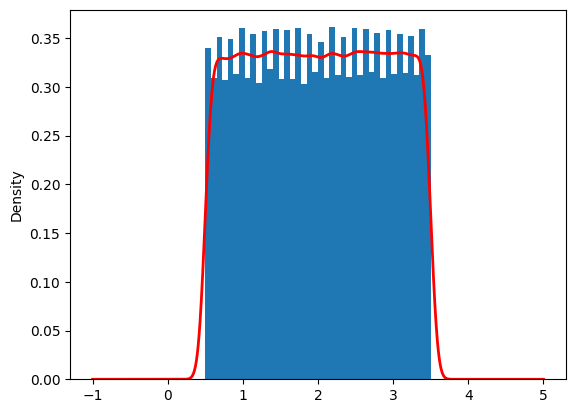

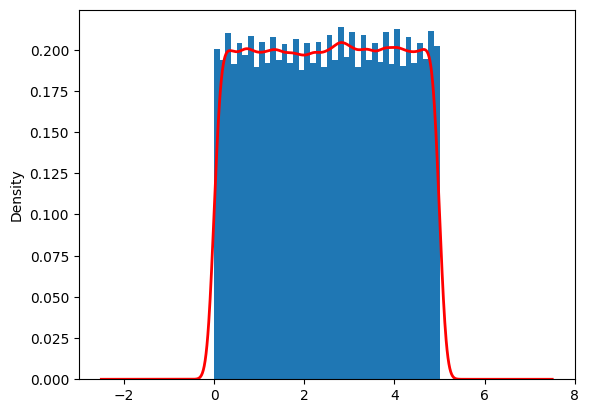

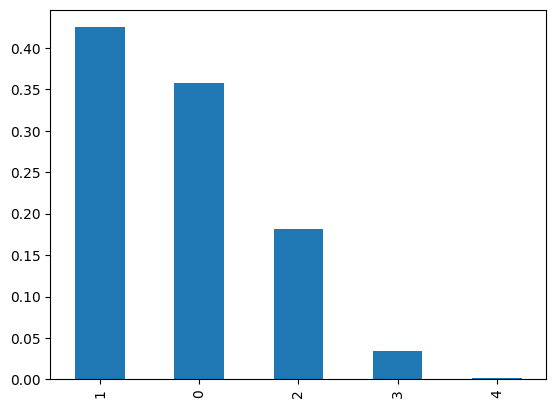

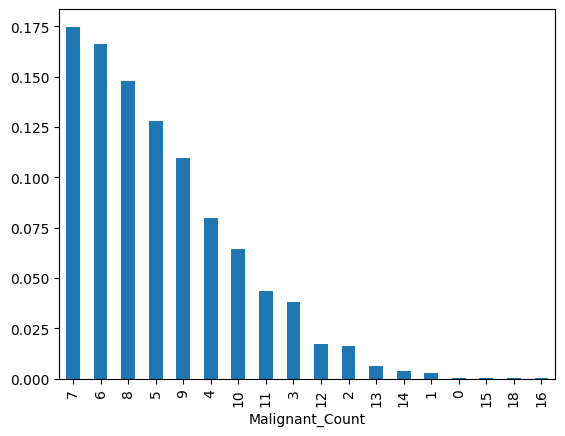

fa Likely Discrete
fb Likely Discrete
fc Likely Discrete
fd Likely Discrete


In [71]:
fA.plot.hist(bins=40,density=True)
fA.plot.kde(color='red',linewidth=2)
plt.show()

fB.plot.hist(bins=40,density=True)
fB.plot.kde(color='red',linewidth=2)
plt.show()

# fC.plot.hist(bins=40,density=True)
# fC.plot.kde(color='red',linewidth=2)
pmf = fC.value_counts(normalize=True)
pmf.plot.bar()
plt.show()

# fD.plot.hist(bins=40,density=True)
# fD.plot.kde(color='red',linewidth=2)
pmf = fD.value_counts(normalize=True)
pmf.plot.bar()
plt.show()

if fA.nunique()/len(df) < 0.5:
    print("fa Likely Discrete")
if fB.nunique()/len(df) < 0.5:
    print("fb Likely Discrete")
if fC.nunique()/len(df) < 0.05:
    print("fc Likely Discrete")
if fD.nunique()/len(df) < 0.05:
    print("fd Likely Discrete")

In [53]:
print(fA.min(),fA.max())
print(fB.min(),fB.max())
print(fC.min(),fC.max())
print(fD.min(),fD.max())

0.5 3.5
0.0 5.0
0 4
0 18


In [63]:
if (abs(fA.skew()) < 0.005):
    print("FA is symmetric")
else:
    print(("FA is not symmetric"))
    
if (abs(fB.skew()) < 0.005):
    print("FB is symmetric")
else:
    print(("FB is not symmetric"))
    
if (abs(fC.skew()) < 0.005):
    print("FC is symmetric")
else:
    print(("FC is not symmetric"))
    
if (abs(fD.skew()) < 0.005):
    print("FD is symmetric")
else:
    print(("FD is not symmetric"))
    

FA is symmetric
FB is symmetric
FC is not symmetric
FD is not symmetric
